# 05 · Validation-tuned CBF + CF + KG
Keep the legacy model intact; save the genuine-KG hybrid as a separate artifact.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if str(ROOT.parent) not in sys.path: sys.path.insert(0,str(ROOT.parent))
from ml.src.preprocessing import load_data, read_json, save_json
from ml.src.evaluation import evaluate, feature_groups
from ml.src.notebook_helpers import table, metric_row, chart
from IPython.display import display, Code
import matplotlib.pyplot as plt
%matplotlib inline


The new score is `w_CBF×CBF + w_CF×CF + w_KG×KG`. Before evaluating the test set we fix the architecture constraint: each component receives at least 10% weight. Select among the 36 feasible 0.1-step combinations using validation MAP@3 only. This constraint may reduce performance compared with an unrestricted or quality-only model; it is not a claim of superiority. The fixed benchmark was previously inspected, so new comparisons are retrospective, not fresh blind-test evidence. Operational context has zero role in NetEase evaluation.

"Weights [CBF, CF, KG]",Validation MAP@3 %
"[0.1, 0.5, 0.4]",76.5142
"[0.1, 0.8, 0.1]",76.5004
"[0.1, 0.4, 0.5]",76.4894
"[0.1, 0.6, 0.3]",76.393
"[0.1, 0.3, 0.6]",76.3517
"[0.1, 0.7, 0.2]",76.3407
"[0.1, 0.2, 0.7]",76.1287
"[0.2, 0.6, 0.2]",76.1026
"[0.2, 0.7, 0.1]",76.1012
"[0.1, 0.1, 0.8]",76.0668


Saved weights: [0.1, 0.5, 0.4]


Model,Top-1 %,P@3 %,R@3 %,MAP@3 %,Full MAP %,NDCG@3 %
Selected KG hybrid / validation,83.35,81.12,65.193,76.514,85.663,81.786


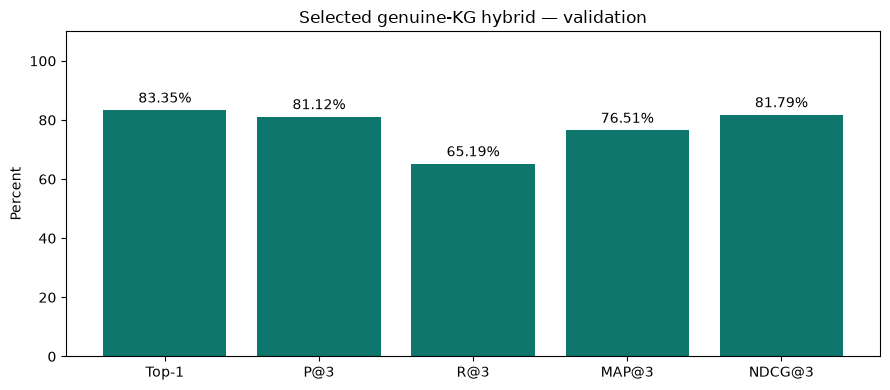

In [2]:
from ml.src.hybrid import tune
best=tune(); trials=read_json('reports/validation_search.json')
table([{'Weights [CBF, CF, KG]':r['weights'],'Validation MAP@3 %':round(r['metrics']['map_at_k']*100,4)} for r in sorted(trials,key=lambda r:-r['metrics']['map_at_k'])[:10]])
print('Saved weights:',best['weights'])
table([metric_row('Selected KG hybrid / validation',best['metrics'])])
chart('Selected genuine-KG hybrid — validation',best['metrics'],'hybrid.png')

In application_demo mode only, optional explicitly supplied availability/capacity can filter candidates and blend 10% free capacity with 90% ML score. Synthetic default display context is not used automatically. Source capability mappings for onboarding task labels must be explicit and documented as demonstration mappings, not learned KYC expertise.